[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jadg1/economic-networks-seminar/blob/main/labs/crisis_networks.ipynb)

**Run it in Google Colab, with nothing to install:** click the badge, then run the setup cell below first. On your own computer the setup cell does nothing.

In [ ]:
# Setup for Google Colab: gets the repository's files and the two extra packages.
# On your own computer (with the econ-networks environment) this cell does nothing.
import os, sys
if "google.colab" in sys.modules:
    REPO = "jadg1/economic-networks-seminar"
    if not os.path.exists("/content/economic-networks-seminar"):
        !git clone -q --depth 1 https://github.com/{REPO}.git /content/economic-networks-seminar
    %cd /content/economic-networks-seminar/labs
    %pip install -q pyreadr pyvis
    print("Ready: running from the repository's labs folder.")

# Who was connected to whom: the 2008 crisis and the Credit Suisse weekend

Economic Networks, Part 2  

Each crisis is a small network of actors (banks, funds, central banks,  
governments) and the links that mattered: losses, rescues, takeovers,  
runs and payments. Amounts are shown only where a source gives them  
(see SOURCES at the bottom).  

Run it to save, for each crisis:  
crisis_2008.png / crisis_2023.png            the whole story in one picture  
crisis_2008_step1.png ... (one per date)     a build to click through on slides  

`Needs: pip install matplotlib`

## Setup

In [1]:
%matplotlib inline

In [2]:
import matplotlib.pyplot as plt
plt.rcParams["text.parse_math"] = False   # so "$" stays a dollar sign
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

INK, MUTED, LINE, PAPER = "#1B1F3B", "#8A8FA8", "#C9CCD8", "#F3F4F8"
ROLE = {   # node fill colour by what happened to the actor
    "failed": "#F2464F", "rescued": "#E89400", "bank": "#2D6CF6",
    "authority": "#12A873", "investors": "#8A8FA8", "trigger": "#7653E8",
}
ROLE_NAME = {"failed": "Failed or taken over", "rescued": "Rescued",
             "bank": "Bank or buyer", "authority": "Central bank, government or regulator",
             "investors": "Investors and clients", "trigger": "Earlier shock"}
LINK = {   # colour, line style, legend name
    "loss": ("#F2464F", "-", "Losses or exposure"),
    "rescue": ("#12A873", "-", "Rescue, loan or guarantee"),
    "takeover": ("#2D6CF6", "-", "Takeover"),
    "payment": ("#7653E8", "-", "Rescue money passed on"),
    "run": ("#E89400", "--", "Run or withdrawals"),
    "confidence": ("#8A8FA8", "--", "Loss of confidence"),
    "legal": ("#8A8FA8", ":", "Legal or policy decision"),
}

## The 2008 crisis

In [3]:
CRISIS_2008 = {
    "title": "2008: one hub was allowed to fail, the other was rescued the next day",
    "nodes": {   # name: (x, y, role)
        "Federal Reserve": (5.0, 9.4, "authority"),
        "US Treasury": (7.2, 0.6, "authority"),
        "Fannie Mae and\nFreddie Mac": (10.0, 0.6, "rescued"),
        "Bear Stearns": (0.9, 7.6, "failed"),
        "JPMorgan": (0.9, 4.9, "bank"),
        "Merrill Lynch": (2.4, 1.6, "failed"),
        "Bank of America": (0.4, 0.2, "bank"),
        "Lehman\nBrothers": (4.2, 6.6, "failed"),
        "Barclays": (6.3, 4.4, "bank"),
        "Reserve Primary\nFund": (4.2, 3.4, "failed"),
        "Money market\ninvestors": (4.2, 0.6, "investors"),
        "AIG": (8.6, 6.6, "rescued"),
        "Société\nGénérale": (12.4, 7.6, "bank"),
        "Deutsche\nBank": (12.4, 5.8, "bank"),
        "Goldman\nSachs": (12.4, 4.0, "bank"),
        "BNP Paribas": (12.4, 2.2, "bank"),
    },
    "edges": [   # (from, to, kind, label, step[, label position along the link])
        ("Bear Stearns", "JPMorgan", "takeover", "sold, March", 1),
        ("Federal Reserve", "JPMorgan", "rescue", "supports the sale", 1),
        ("US Treasury", "Fannie Mae and\nFreddie Mac", "rescue", "taken over, 7 Sep", 2),
        ("Merrill Lynch", "Bank of America", "takeover", "bought, 14 Sep", 3),
        ("Barclays", "Lehman\nBrothers", "legal", "rescue talks fail", 3),
        ("Lehman\nBrothers", "Reserve Primary\nFund", "loss", "$785m of Lehman debt", 4),
        ("Reserve Primary\nFund", "Money market\ninvestors", "run", "breaks the buck, 16 Sep", 5),
        ("Federal Reserve", "AIG", "rescue", "$85bn loan, 16 Sep", 5),
        ("US Treasury", "Reserve Primary\nFund", "rescue", "guarantees money funds, 19 Sep", 6, 0.28),
        ("AIG", "Société\nGénérale", "payment", "$4.1bn", 7),
        ("AIG", "Deutsche\nBank", "payment", "$9.0bn", 7),
        ("AIG", "Goldman\nSachs", "payment", "$7.3bn", 7),
        ("AIG", "BNP Paribas", "payment", "$4.9bn", 7),
        ("AIG", "Barclays", "payment", "$7.0bn", 7),
    ],
    "steps": {
        1: "March 2008: Bear Stearns is sold to JPMorgan, with Fed support",
        2: "7 September: the government takes over Fannie Mae and Freddie Mac",
        3: "13–14 September: Bank of America buys Merrill Lynch; talks to save Lehman fail",
        4: "15 September: Lehman files for bankruptcy; a money market fund holds $785m of its debt",
        5: "16 September: the fund breaks the buck and investors run; the Fed lends AIG $85bn",
        6: "19 September: the Treasury guarantees money market funds to stop the run",
        7: "September to December: AIG passes rescue money on to the biggest banks",
    },
    "note": "AIG amounts: collateral on credit default swaps plus securities lending, "
            "16 Sep to 31 Dec 2008 (Deutsche $2.6bn + $6.4bn, Goldman $2.5bn + $4.8bn).",
}

## The Credit Suisse weekend, March 2023

In [4]:
CRISIS_2023 = {
    "title": "2023: a run on Credit Suisse, stopped by merging it into a bigger hub",
    "nodes": {
        "Archegos": (0.6, 8.6, "trigger"),
        "Greensill": (0.6, 6.4, "trigger"),
        "Clients": (0.6, 3.6, "investors"),
        "Silicon Valley\nBank (US)": (4.0, 9.4, "failed"),
        "Saudi National\nBank": (7.6, 9.4, "investors"),
        "Credit Suisse": (4.0, 5.8, "failed"),
        "Swiss National\nBank": (8.6, 8.0, "authority"),
        "UBS": (8.6, 4.8, "bank"),
        "Swiss\ngovernment": (12.4, 6.6, "authority"),
        "Shareholders": (12.4, 3.4, "investors"),
        "AT1\nbondholders": (4.0, 2.2, "investors"),
        "FINMA\n(regulator)": (8.6, 1.4, "authority"),
        "Federal\nAdministrative\nCourt": (12.4, 0.4, "authority"),
    },
    "edges": [
        ("Archegos", "Credit Suisse", "loss", "about $5.5bn loss, 2021", 1),
        ("Greensill", "Credit Suisse", "loss", "about $10bn of funds frozen, 2021", 1),
        ("Clients", "Credit Suisse", "run", "CHF 110.5bn withdrawn, late 2022", 2),
        ("Silicon Valley\nBank (US)", "Credit Suisse", "confidence", "collapses 10 Mar", 3),
        ("Saudi National\nBank", "Credit Suisse", "confidence", "9.9% owner: no more capital, 15 Mar", 4),
        ("Swiss National\nBank", "Credit Suisse", "rescue", "up to CHF 50bn, 16 Mar", 5),
        ("Credit Suisse", "UBS", "takeover", "bought for about CHF 3bn, 19 Mar", 6),
        ("Swiss\ngovernment", "UBS", "rescue", "covers some losses", 6),
        ("Swiss\ngovernment", "Shareholders", "legal", "no shareholder vote", 6),
        ("FINMA\n(regulator)", "AT1\nbondholders", "legal", "CHF 16bn written down", 6),
        ("Federal\nAdministrative\nCourt", "FINMA\n(regulator)", "legal", "write-down unlawful, Oct 2025 (appealed)", 7, 0.55),
    ],
    "steps": {
        1: "2021: losses on Archegos and frozen Greensill funds damage Credit Suisse",
        2: "Late 2022: clients withdraw CHF 110.5bn in three months",
        3: "10 March 2023: Silicon Valley Bank collapses; investors flee weaker banks",
        4: "15 March: the largest shareholder says it can't add capital; shares fall 24%",
        5: "16 March: the Swiss National Bank offers up to CHF 50bn; the run continues",
        6: "19 March: UBS takes over Credit Suisse; AT1 bonds wiped out, shareholders get no vote",
        7: "October 2025: a Swiss court rules the AT1 write-down unlawful; FINMA appeals",
    },
    "note": "UBS's balance sheet is now roughly twice Swiss GDP. "
            "Careful: Saudi National Bank (a shareholder) is not the Swiss National Bank.",
}

## Drawing

In [5]:
def draw_crisis(crisis, upto=None, path=None):
    """Draw the network. upto = a step number: links up to that step are shown,
    the newest step highlighted, later ones hidden. upto=None draws everything."""
    last = max(crisis["steps"])
    upto = last if upto is None else upto
    fig, ax = plt.subplots(figsize=(14, 8.2))
    ax.set_xlim(-1.2, 14.0)
    ax.set_ylim(-0.8, 11.3)
    ax.axis("off")

    shown = [e for e in crisis["edges"] if e[4] <= upto]
    active = {n for e in shown for n in e[:2]}
    building = upto < last

    # links
    for a, b, kind, label, step, *where in shown:
        t = where[0] if where else 0.5
        (xa, ya, _), (xb, yb, _) = crisis["nodes"][a], crisis["nodes"][b]
        col, ls, _ = LINK[kind]
        new = building and step == upto
        alpha = 1 if (new or not building) else 0.35
        arrow = FancyArrowPatch((xa, ya), (xb, yb), arrowstyle="-|>", mutation_scale=16,
                                color=col, lw=3.2 if new else 2, ls=ls, alpha=alpha,
                                shrinkA=34, shrinkB=34, connectionstyle="arc3,rad=0.06",
                                zorder=1)
        ax.add_patch(arrow)
        ax.text(xa + (xb - xa) * t, ya + (yb - ya) * t + 0.05, label, ha="center", va="center",
                fontsize=8.5, color=INK if alpha == 1 else MUTED, zorder=3,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none",
                          alpha=0.9 if alpha == 1 else 0.6))

    # actors
    for name, (x, y, role) in crisis["nodes"].items():
        on = name in active or not building
        ax.text(x, y, name, ha="center", va="center", fontsize=10, fontweight="bold",
                color="white" if on else MUTED, zorder=4,
                bbox=dict(boxstyle="round,pad=0.5", lw=0,
                          fc=ROLE[role] if on else PAPER))

    # title, the step's caption, legend, note
    ax.text(-1.1, 11.2, crisis["title"], fontsize=14, fontweight="bold", color=INK, va="top")
    if building:
        ax.text(-1.1, 10.6, f"Step {upto} of {last}.  {crisis['steps'][upto]}",
                fontsize=11, color=INK, va="top")
    kinds = sorted({e[2] for e in crisis["edges"]}, key=list(LINK).index)
    roles = sorted({r for *_, r in crisis["nodes"].values()}, key=list(ROLE).index)
    handles = [Line2D([], [], color=LINK[k][0], ls=LINK[k][1], lw=2.5, label=LINK[k][2]) for k in kinds]
    handles += [Line2D([], [], marker="s", ls="", ms=11, color=ROLE[r], label=ROLE_NAME[r]) for r in roles]
    fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.045), ncol=4,
               frameon=False, fontsize=9)
    fig.text(0.02, 0.012, crisis["note"], fontsize=8.5, color=MUTED, va="bottom")
    fig.tight_layout(rect=(0, 0.13, 1, 1))
    if path:
        fig.savefig(path, dpi=160)
        plt.close(fig)
    return fig


def save_build(crisis, prefix):
    """One picture per step, to click through on consecutive slides."""
    for s in crisis["steps"]:
        draw_crisis(crisis, upto=s, path=f"{prefix}_step{s}.png")
    draw_crisis(crisis, path=f"{prefix}.png")

## The network reading, computed

In [6]:
def network_reading(crisis):
    """Who is most connected in each crisis picture?"""
    from collections import Counter
    links = Counter()
    for a, b, *_ in crisis["edges"]:
        links[a] += 1
        links[b] += 1
    name = lambda n: n.replace("\n", " ")
    return ", ".join(f"{name(n)} ({k})" for n, k in links.most_common(4))

In [7]:
for crisis, prefix in [(CRISIS_2008, "crisis_2008"), (CRISIS_2023, "crisis_2023")]:
    save_build(crisis, prefix)
    print(f"{prefix}: saved {len(crisis['steps'])} steps + the full picture. "
          f"Most links: {network_reading(crisis)}")

crisis_2008: saved 7 steps + the full picture. Most links: AIG (6), Reserve Primary Fund (3), JPMorgan (2), Federal Reserve (2)


crisis_2023: saved 7 steps + the full picture. Most links: Credit Suisse (7), UBS (2), Swiss government (2), FINMA (regulator) (2)


### Look at them here
The cell above saves every step as a PNG for the slides. These two cells draw the full pictures in the notebook. For one step, use e.g. `draw_crisis(CRISIS_2008, upto=3)`.

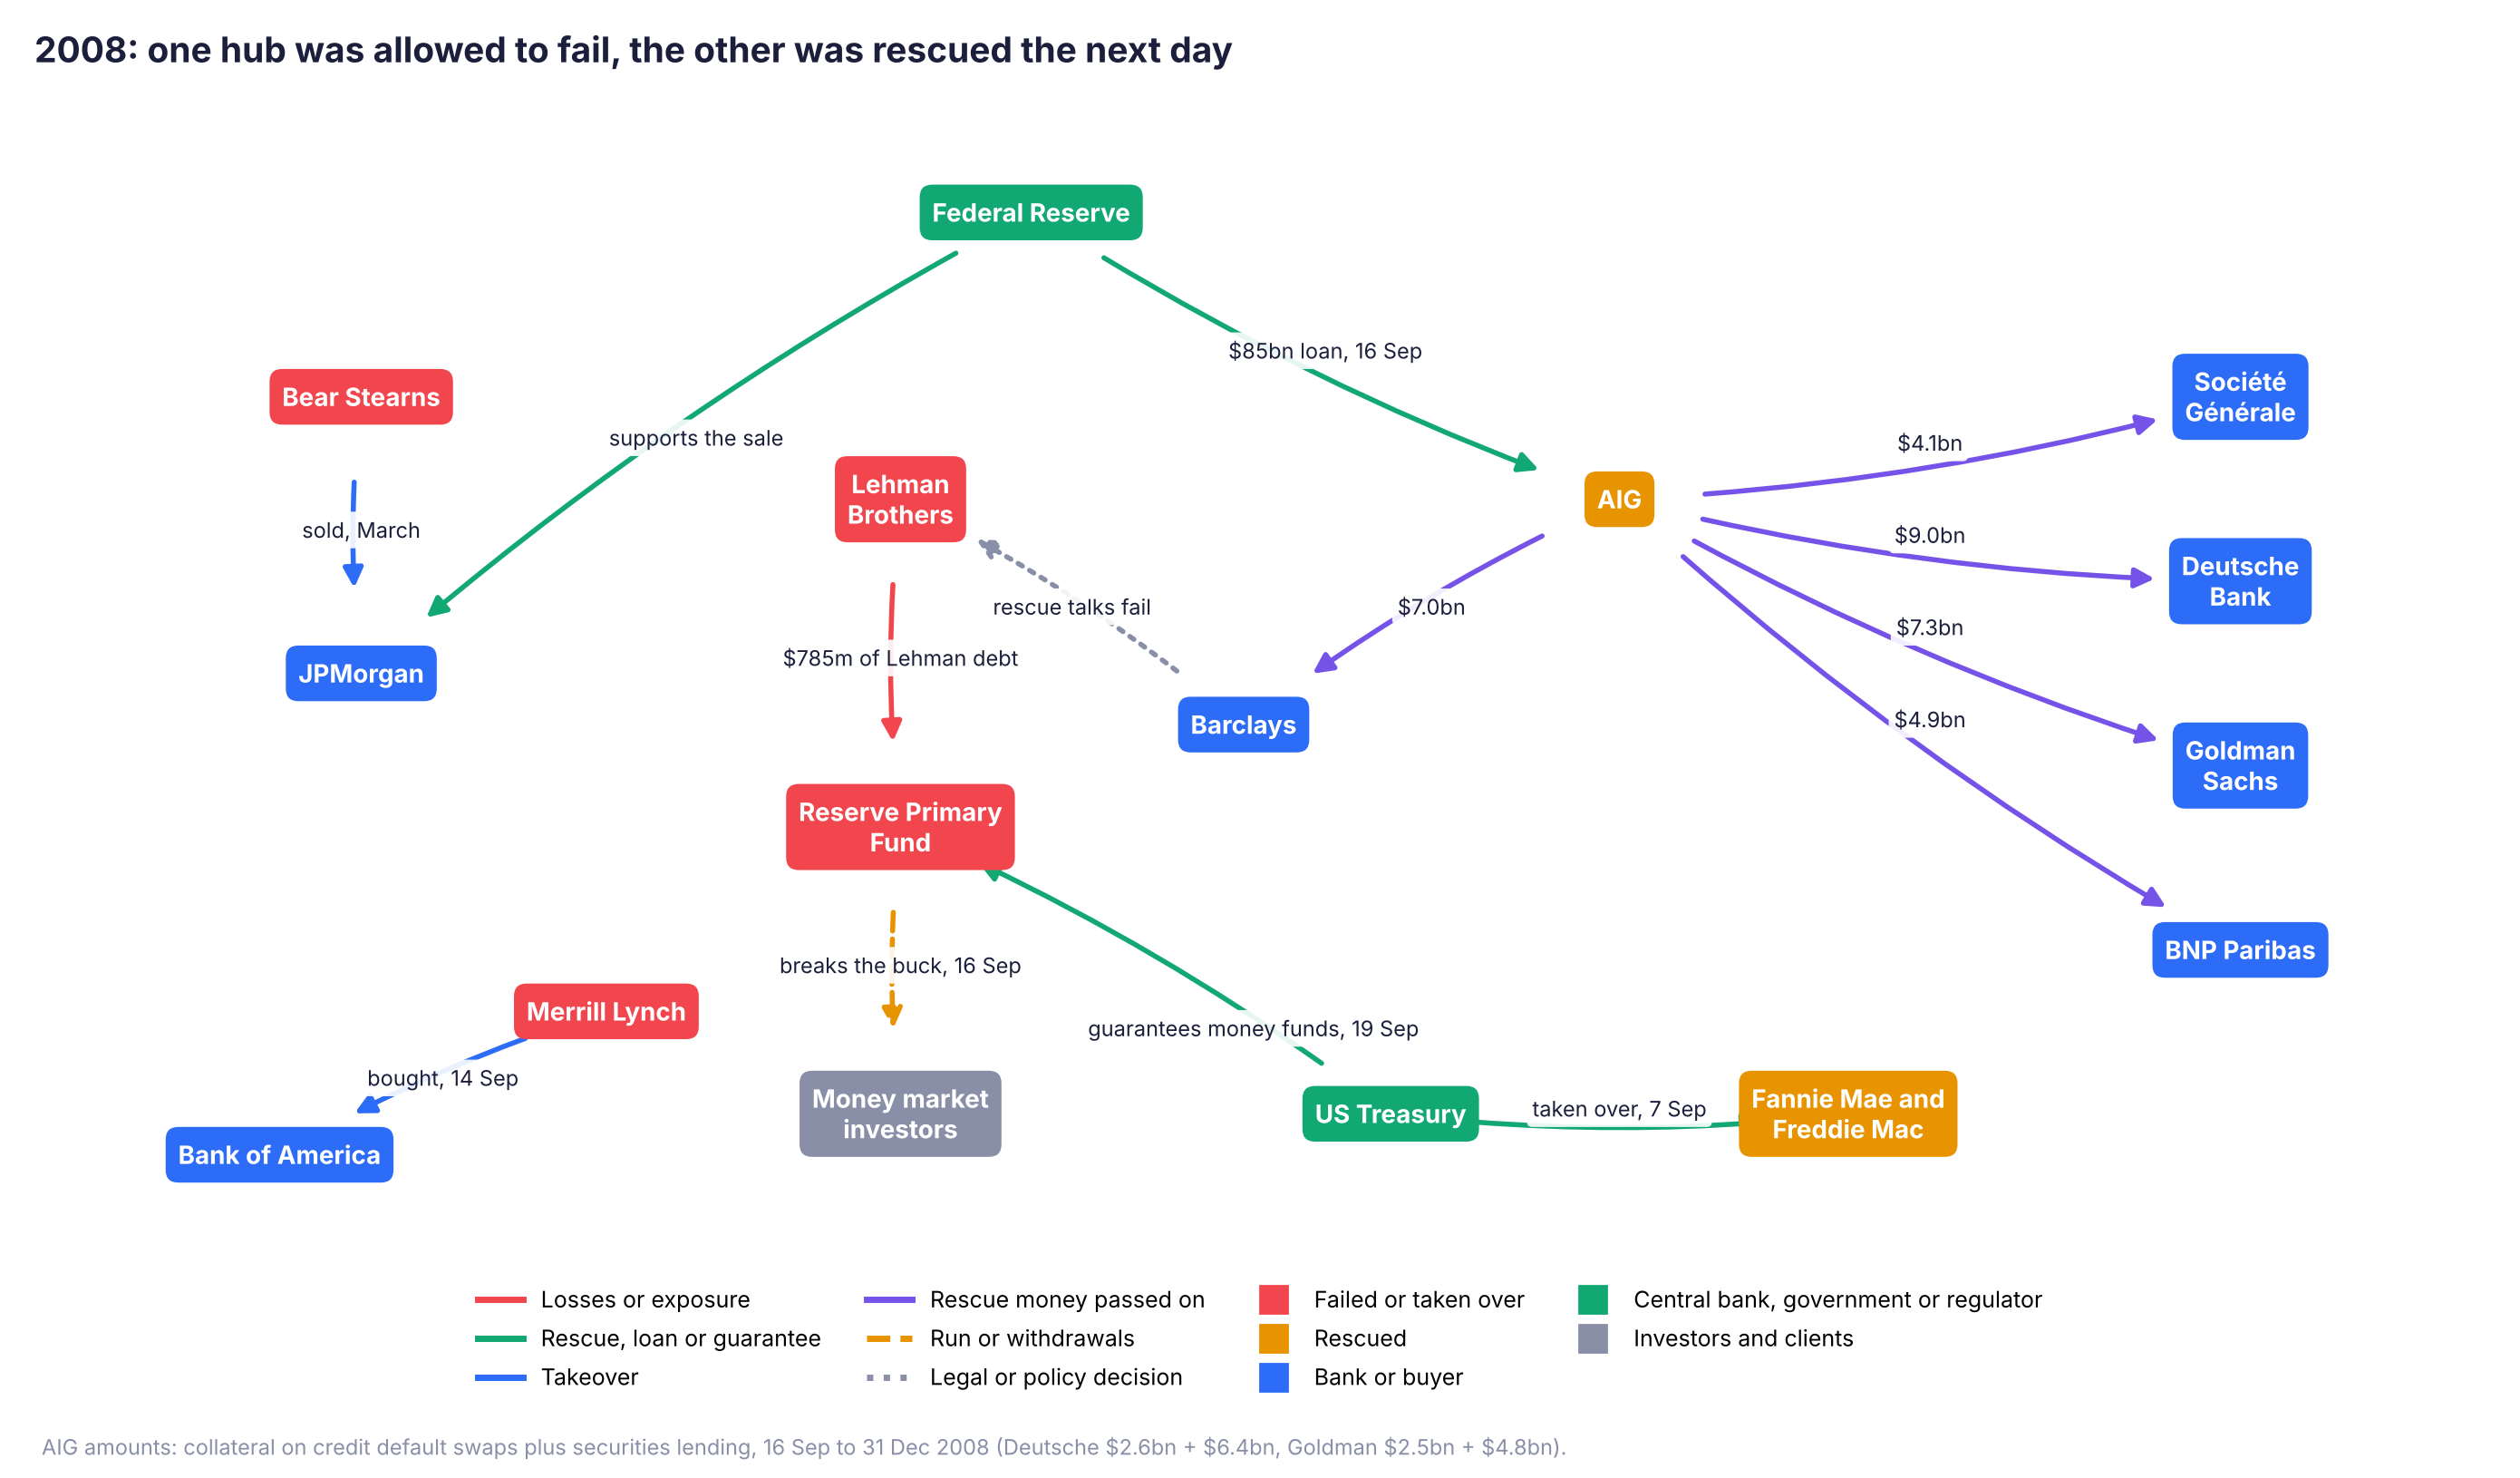

In [8]:
draw_crisis(CRISIS_2008);

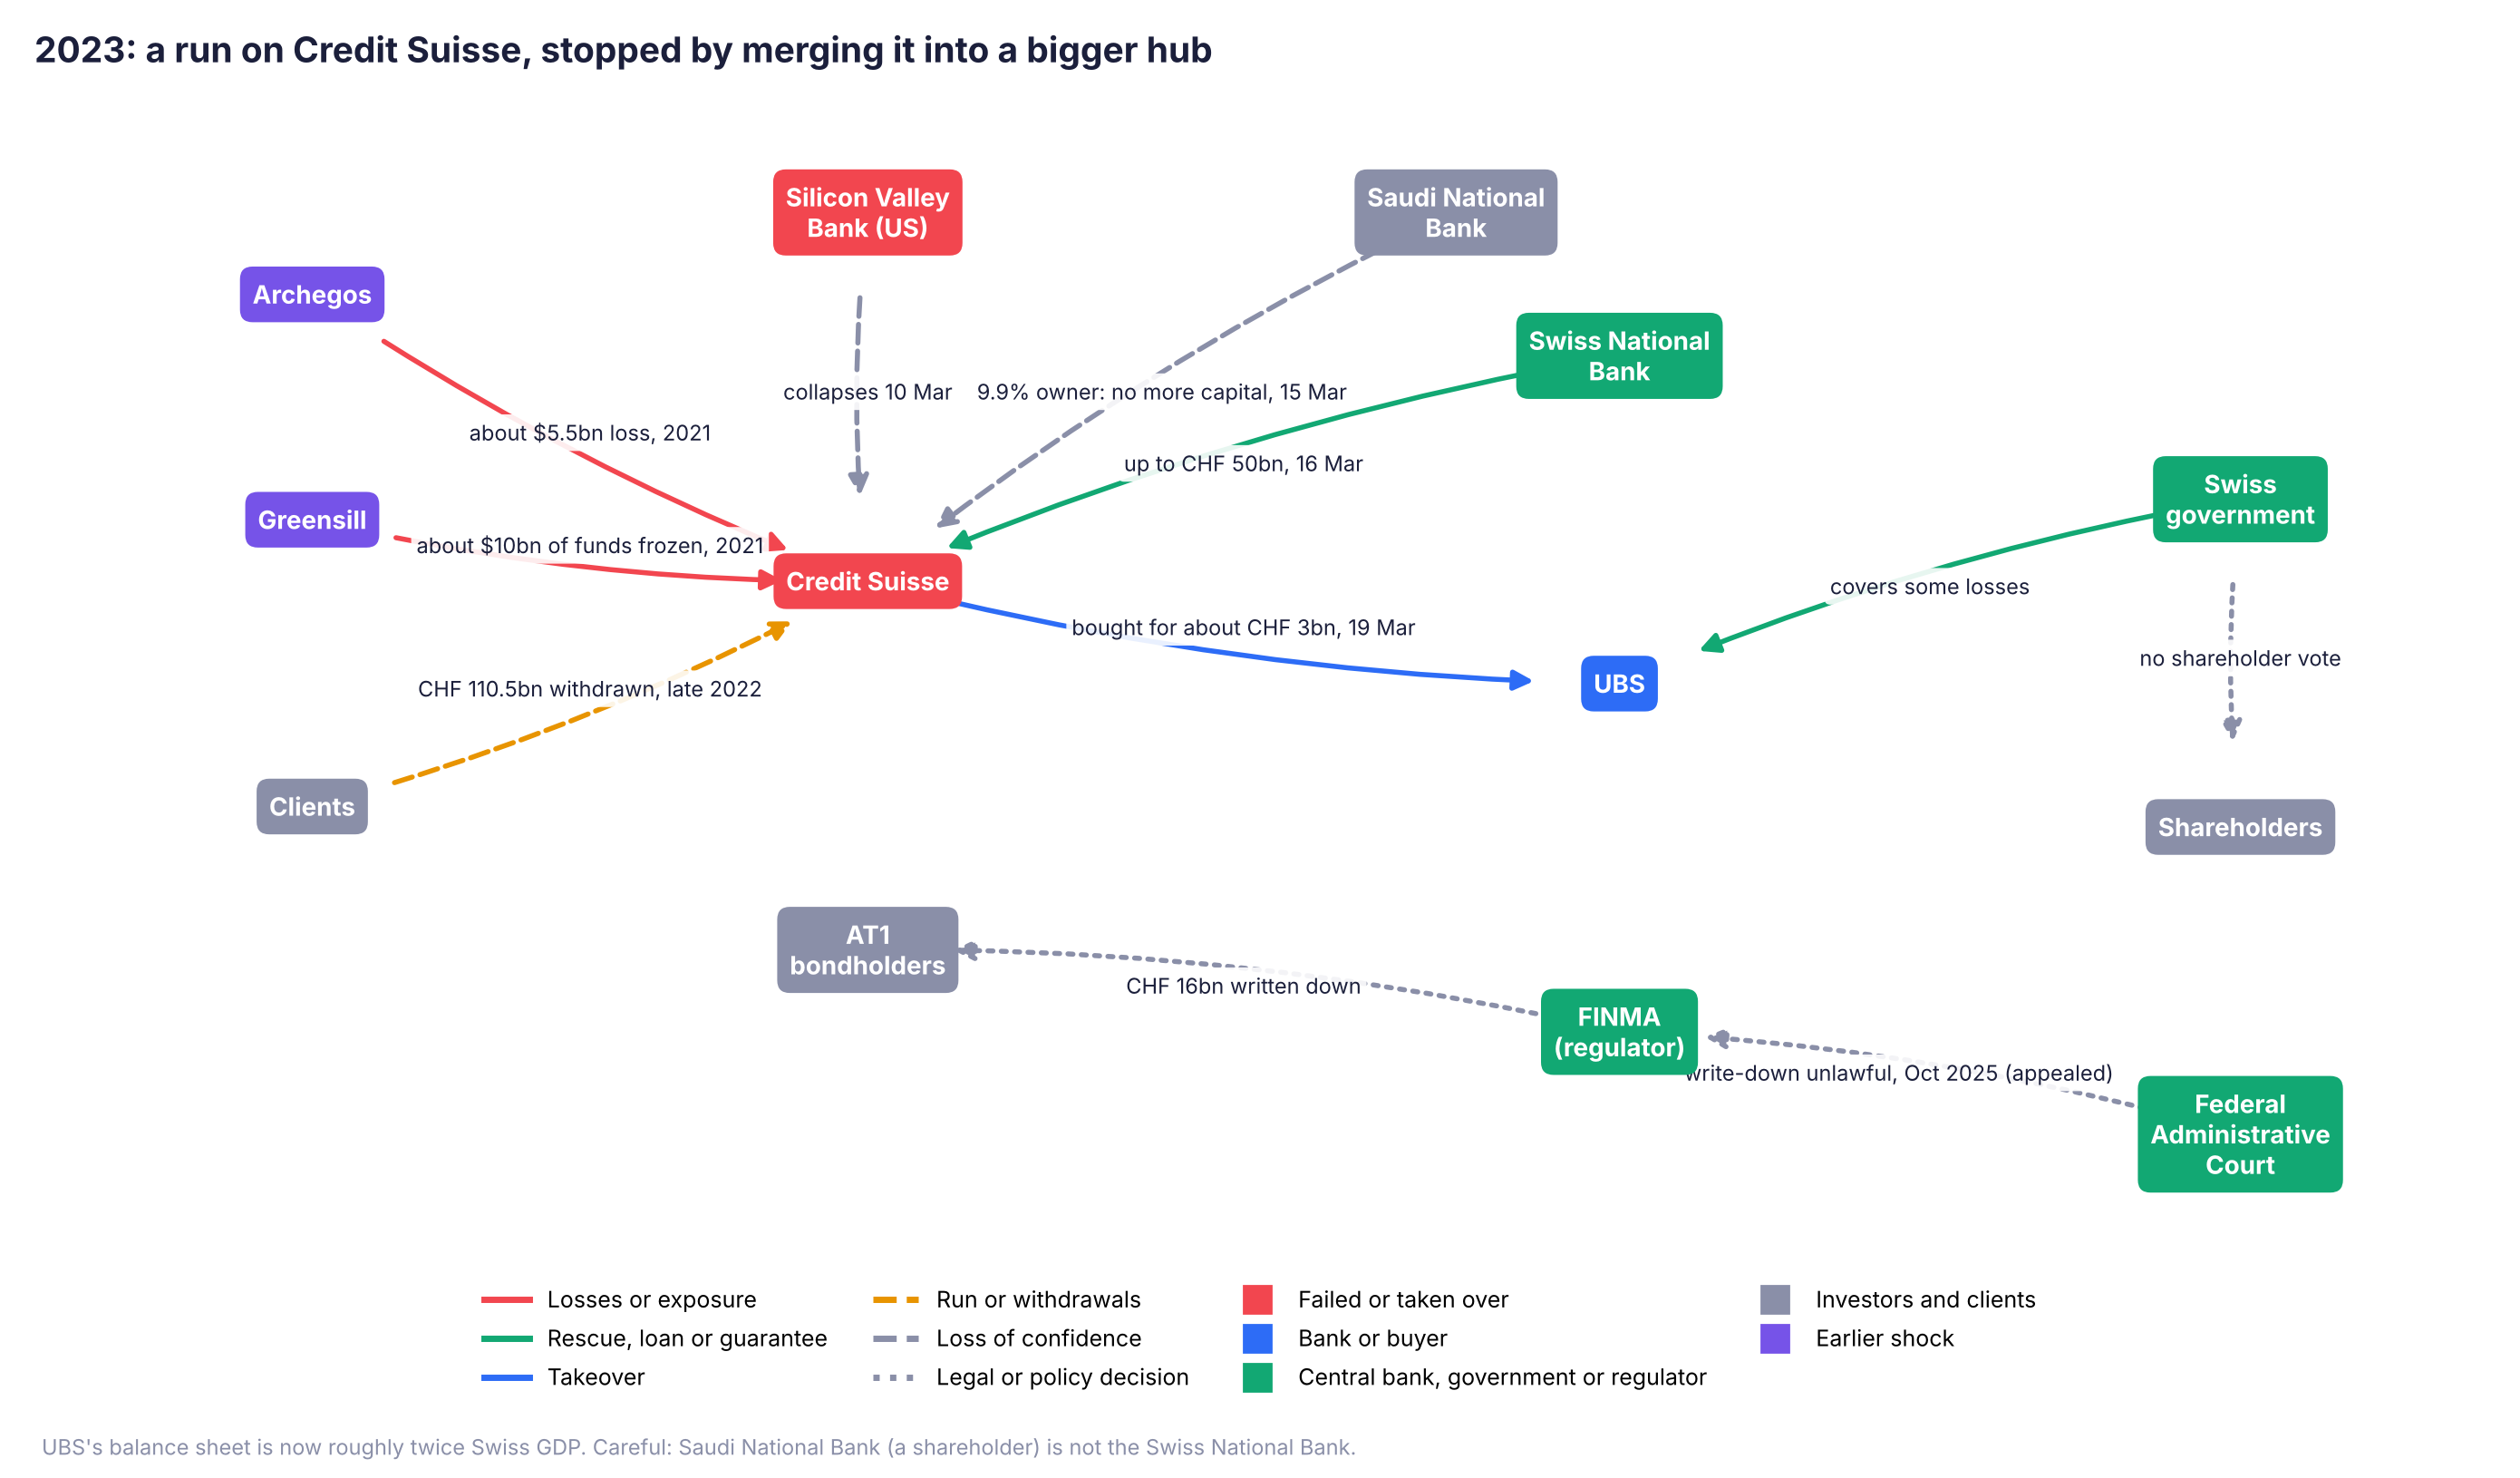

In [9]:
draw_crisis(CRISIS_2023);

In [10]:
SOURCES = """
2008: Britannica (Lehman); CNBC (AIG counterparty payments); Columbia Journalism
Review and Federal Reserve Bank of Boston (Reserve Primary Fund).
2023: The Star (Credit Suisse 2022 loss and outflows); Convextrade (timeline);
The TRADE (deal terms); FINMA statements of 19 March 2023 and 15 October 2025;
The National (UBS balance sheet relative to Swiss GDP).
Full links are in the seminar's teaching notes.
"""